# Erdős–Rényi Random Graphs

So far a graph was a *single* object: an adjacency matrix, a degree sequence, a set of edges.
The Erdős–Rényi model replaces that object by a **probability distribution over graphs**.
We can then ask questions such as "how many edges does a typical graph have?" or "when does a giant
connected component appear?", and answer them exactly — and check the answers by simulation.

**Reading.** Blum, Hopcroft & Kannan, *Foundations of Data Science*, Ch. 4; van Steen,
*Graph Theory and Complex Networks*, Ch. 3.

## Why model graphs randomly?

- **Null model.** What does a network look like when there is *no* structure at all? Anything that
  the random model does *not* produce (heavy-tailed degrees, many triangles, small diameter) is what
  we mean by "structure" in real data.
- **Generative model.** Statements such as "most graphs are connected" hold *with high probability*
  (whp) — for a single graph they are simply true or false.
- **Testbed.** Community detection, spectral clustering or PageRank are first tested on random
  graphs, where the correct answer is known by construction.

In [1]:
%matplotlib inline
import math
from collections import Counter

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

plt.rcParams["figure.figsize"] = (6, 4)
rng = np.random.default_rng(7)

## The two models

**Definition (Erdős–Rényi, $G(n,p)$).** Fix $n$ vertices. For each of the
$\binom{n}{2}$ unordered pairs, insert the edge independently with probability $p$.

**Definition ($G(n,m)$).** All graphs with $n$ vertices and exactly $m$ edges are equally likely.

The two are closely related: $G(n,m)$ is $G(n,p)$ *conditioned* on having exactly $m$ edges (with
$p = m / \binom{n}{2}$), and for large $n$ the conditioning changes almost nothing.

In [2]:
n, p = 200, 0.05
G1 = nx.gnp_random_graph(n, p, seed=1)          # G(n, p)
G2 = nx.gnm_random_graph(n, nx.gnp_random_graph(n, p, seed=2).number_of_edges(), seed=3)  # G(n, m)

print("n =", n, " p =", p, " number of possible pairs =", math.comb(n, 2))
print("G(n,p) edges:", G1.number_of_edges(), "   G(n,m) edges:", G2.number_of_edges())

n = 200  p = 0.05  number of possible pairs = 19900
G(n,p) edges: 1025    G(n,m) edges: 996


## Number of edges

Let $N = \binom{n}{2}$. The number of edges $M$ is a sum of $N$ independent Bernoulli$(p)$ variables,
hence

$$
M \sim \mathrm{Bin}\!\left(N, p\right),
\qquad
\mathbb{E}[M] = Np,
\qquad
\mathrm{Var}(M) = Np(1-p).
$$

The mean degree follows immediately: $\bar d = 2\,\mathbb{E}[M]/n = (n-1)p$.

In [3]:
n, p, reps = 500, 0.05, 2000
N = math.comb(n, 2)

counts = np.array([nx.gnp_random_graph(n, p, seed=s).number_of_edges() for s in range(reps)])

print(f"theory : mean = {N*p:.1f}   std = {math.sqrt(N*p*(1-p)):.2f}")
print(f"empirical: mean = {counts.mean():.1f}   std = {counts.std():.2f}")

theory : mean = 6237.5   std = 76.98
empirical: mean = 6239.1   std = 77.34


## The degree distribution

The degree of one fixed vertex is the number of successes among the $n-1$ pairs that contain it:

$$
D \sim \mathrm{Bin}(n-1, p),
\qquad
\mathbb{E}[D] = (n-1)p,
\qquad
\mathrm{Var}(D) = (n-1)p(1-p).
$$

### Poisson limit

The interesting regime is a **constant average degree** $c$: take $p = c/(n-1)$ and let $n\to\infty$.
Then $\mathbb{E}[D] = c$ and

$$
\Pr(D = k) = \binom{n-1}{k} p^k (1-p)^{n-1-k}
\;\xrightarrow[n\to\infty]{}\;
e^{-c}\,\frac{c^k}{k!}.
$$

(The first factor behaves like $(n-1)^k/k!$, the last one like $e^{-c}$.) So a *large* sparse
Erdős–Rényi graph has Poisson degrees: most vertices have degree close to $c$, and the maximum degree
is only $O(\log n / \log\log n)$. Real networks look very different — see the last section.

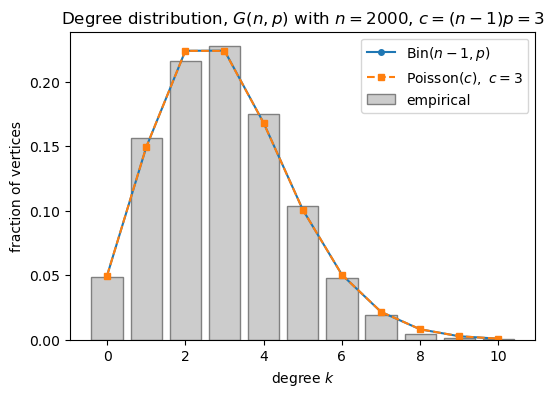

mean degree: empirical = 2.961  theory c = 3


In [4]:
n, c = 2000, 3
p = c / (n - 1)
G = nx.gnp_random_graph(n, p, seed=11)

degrees = np.array([d for _, d in G.degree()])
k = np.arange(0, degrees.max() + 1)

binomial = [math.comb(n - 1, int(i)) * p**i * (1 - p) ** (n - 1 - i) for i in k]
poisson = [math.exp(-c) * c**i / math.factorial(int(i)) for i in k]

plt.bar(k, np.bincount(degrees, minlength=len(k)) / n, width=0.8,
        label="empirical", color="0.8", edgecolor="0.5")
plt.plot(k, binomial, "o-", ms=4, label=r"$\mathrm{Bin}(n-1,p)$")
plt.plot(k, poisson, "s--", ms=4, label=r"$\mathrm{Poisson}(c),\ c=3$")
plt.xlabel("degree $k$")
plt.ylabel("fraction of vertices")
plt.title(f"Degree distribution, $G(n,p)$ with $n={n}$, $c=(n-1)p=3$")
plt.legend()
plt.show()

print("mean degree: empirical =", degrees.mean().round(3), " theory c =", c)

## Triangles and clustering

For a fixed triple of vertices to form a triangle, its three edges must be present:

$$
\mathbb{E}\big[\#\text{triangles}\big] = \binom{n}{3} p^3 .
$$

The *local clustering coefficient* of a vertex $v$ is the fraction of pairs of its neighbours that are
themselves connected. In $G(n,p)$ those edges are independent of the neighbourhood, so on average

$$
\mathbb{E}[C_v] \approx p ,
$$

which is tiny for the sparse graphs we care about ($p = c/n$). **This is the main defect of the
model:** real social networks have clustering coefficients of order $10^{-1}$ while $p$ is of order
$10^{-3}$.

p =  0.01 | avg clustering = 0.0118 (p = 0.0100) | triangles: measured     11, theory      10.6
p =  0.02 | avg clustering = 0.0202 (p = 0.0200) | triangles: measured     82, theory      84.7
p =  0.05 | avg clustering = 0.0532 (p = 0.0500) | triangles: measured   1359, theory    1323.4
p =  0.10 | avg clustering = 0.1007 (p = 0.1000) | triangles: measured  10785, theory   10586.8
p =  0.20 | avg clustering = 0.2005 (p = 0.2000) | triangles: measured  84181, theory   84694.4


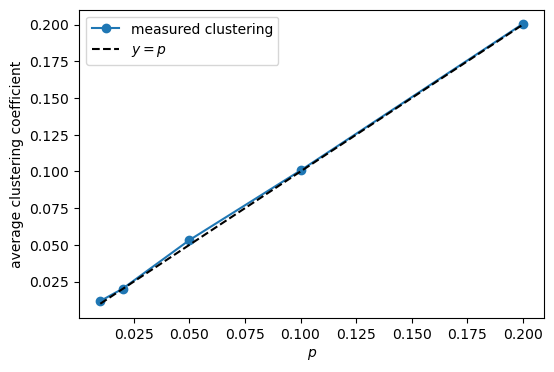

In [5]:
n = 400
ps = np.array([0.01, 0.02, 0.05, 0.1, 0.2])
clustering, expected_triangles, measured_triangles = [], [], []

for p in ps:
    G = nx.gnp_random_graph(n, p, seed=21)
    clustering.append(nx.average_clustering(G))
    expected_triangles.append(math.comb(n, 3) * p**3)
    measured_triangles.append(sum(nx.triangles(G).values()) // 3)

for p, cl, eT, mT in zip(ps, clustering, expected_triangles, measured_triangles):
    print(f"p = {p:5.2f} | avg clustering = {cl:.4f} (p = {p:.4f}) | triangles: measured {mT:6d}, theory {eT:9.1f}")

plt.plot(ps, clustering, "o-", label="measured clustering")
plt.plot(ps, ps, "k--", label=r"$y=p$")
plt.xlabel("$p$")
plt.ylabel("average clustering coefficient")
plt.legend()
plt.show()

## Thresholds: the graph changes qualitatively as $p$ grows

Most statements about $G(n,p)$ are **threshold statements**: there is a value $p^*(n)$ such that
below it a property holds whp, and above it fails whp (or vice versa).

| Property | Threshold | Typical picture |
|---|---|---|
| at least one edge | $p \asymp n^{-2}$ | isolated edges |
| a fixed subgraph with $k$ vertices, $\ell$ edges | $p \asymp n^{-k/\ell}$ | e.g. triangles at $p\asymp n^{-1}$ |
| a tree on $k$ vertices | $p \asymp n^{-k/(k-1)}$ | e.g. paths of length 2 at $p\asymp n^{-2/3}$ |
| **giant component** | $p \asymp 1/n$ | mean degree $c=1$ |
| **connectivity** | $p \asymp \log n / n$ | every vertex has a neighbour |

The last two are the ones we care about. Both are read off the number of *isolated* vertices: for
$p = c\log n / n$,

$$
\mathbb{E}\big[\#\text{isolated}\big] = n(1-p)^{n-1} \approx n\,e^{-c\log n} = n^{1-c},
$$

which tends to $0$ when $c>1$ and to $\infty$ when $c<1$ — hence the threshold $\log n / n$.

In [6]:
n = 500
cs = [0.6, 0.8, 1.0, 1.2, 1.5]
print(f"{'c':>5} {'p':>10} {'isolated (measured)':>20} {'n^(1-c)':>10}")
for c in cs:
    p = c * math.log(n) / n
    G = nx.gnp_random_graph(n, p, seed=int(100 * c))
    isolated = sum(1 for _, d in G.degree() if d == 0)
    print(f"{c:5.2f} {p:10.6f} {isolated:20d} {n ** (1 - c):10.2f}")

    c          p  isolated (measured)    n^(1-c)
 0.60   0.007458                   18      12.01
 0.80   0.009943                    1       3.47
 1.00   0.012429                    3       1.00
 1.20   0.014915                    0       0.29
 1.50   0.018644                    0       0.04


## The giant component (a preview)

Take $p = c/n$ and let $S$ be the fraction of vertices in the largest component.
A branching-process argument (each neighbour has on average $c$ further neighbours) gives the
self-consistency equation

$$
S = 1 - e^{-cS},
$$

whose non-zero solution exists exactly when $c > 1$. This is the **phase transition**: for $c<1$ all
components are of size $O(\log n)$, for $c>1$ a positive fraction of the vertices sits in one
component. The next page derives this in detail; here we only check it experimentally.

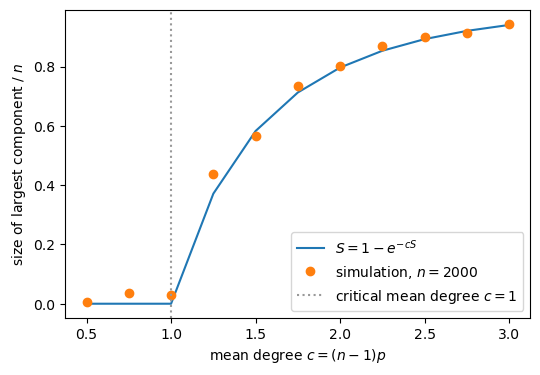

In [7]:
def giant_fraction_theory(c):
    """Solve S = 1 - exp(-c S) by fixed-point iteration (S = 0 is always a solution)."""
    if c <= 1:
        return 0.0
    S = 0.5
    for _ in range(200):
        S = 1 - math.exp(-c * S)
    return S


n = 2000
cs = np.linspace(0.5, 3.0, 11)
measured = []
for c in cs:
    G = nx.gnp_random_graph(n, c / n, seed=int(1000 * c))
    largest = max(len(comp) for comp in nx.connected_components(G))
    measured.append(largest / n)

plt.plot(cs, [giant_fraction_theory(c) for c in cs], "-", label=r"$S = 1-e^{-cS}$")
plt.plot(cs, measured, "o", label=f"simulation, $n={n}$")
plt.axvline(1.0, color="0.6", ls=":", label="critical mean degree $c=1$")
plt.xlabel("mean degree $c = (n-1)p$")
plt.ylabel("size of largest component / $n$")
plt.legend()
plt.show()

## Lab: what a random graph looks like

Keeping $n$ fixed and varying the mean degree $c=(n-1)p$ shows the three regimes: a dust of tiny
components, a critical graph, and a graph dominated by one giant component.

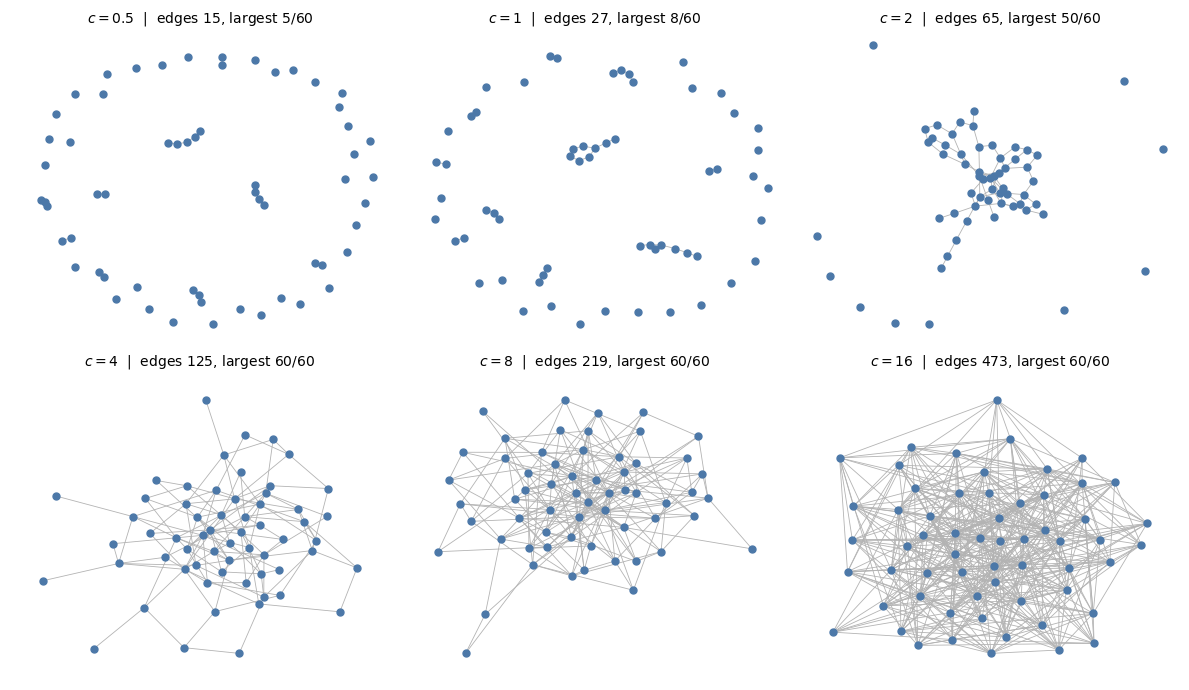

In [8]:
n = 60
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, c in zip(axes.ravel(), [0.5, 1.0, 2.0, 4.0, 8.0, 16.0]):
    G = nx.gnp_random_graph(n, c / (n - 1), seed=int(10 * c) + 5)
    largest = max(len(comp) for comp in nx.connected_components(G))
    nx.draw(G, ax=ax, node_size=25, width=0.6, node_color="#4c78a8", edge_color="0.7")
    ax.set_title(f"$c={c:g}$  |  edges {G.number_of_edges()}, largest {largest}/{n}", fontsize=10)
plt.tight_layout()
plt.show()

## What the model does *not* do

A single parameter cannot describe a real network. Three systematic mismatches motivate the models
that come next in this course:

1. **Degrees.** $G(n,p)$ has Poisson degrees; web graphs, citations and social networks have
   heavy-tailed (power-law) degrees — a few hubs carry a large fraction of the edges.
2. **Clustering.** Triangles are rare ($\mathbb{E}[C_v]\approx p$); in real social networks your
   friends are friends much more often than chance would predict. The **configuration model** (random
   graph with a prescribed degree sequence) and the **Watts–Strogatz small-world model** are the two
   standard repairs.
3. **Geometry.** Distance in $G(n,p)$ is $\Theta(\log n / \log c)$ — very small, but the graph has no
   notion of "close" nodes, which real data (images, cities, the web) usually have.

Still, the Erdős–Rényi graph is the reference point against which all of these are measured.

## Exercises

1. Derive $\mathbb{E}[M]$ and $\mathrm{Var}(M)$ for $G(n,p)$, and use Chebyshev's inequality to show
   that $M/\binom{n}{2} \to p$ in probability.
2. Show that for $p=c/n$ the number of isolated vertices converges in distribution to
   $\mathrm{Poisson}(e^{-c})$ scaled by $n$, and deduce the connectivity threshold $c=\log n$.
3. For fixed $k$, compute the expected number of $k$-cliques and conclude that $k$-cliques appear
   around $p\asymp n^{-2/(k-1)}$.
4. Generate $G(n,m)$ and compare its degree distribution with $G(n,p)$ at $p = 2m/(n(n-1))$; explain
   the small difference you observe.
5. For $n=500,1000,2000$, find empirically the smallest $p$ at which the graph is connected, and
   compare with $\log n / n$. Reproduce the table of thresholds above.
6. *Optional.* Repeat the giant-component experiment for the configuration model with a power-law
   degree sequence and describe how the transition changes.

## References

- P. Erdős and A. Rényi, *On the evolution of random graphs*, Publ. Math. Inst. Hung. Acad. Sci. 5
  (1960), 17–61.
- A. Blum, J. Hopcroft and R. Kannan, *Foundations of Data Science*, Cambridge University Press,
  Ch. 4 (Random Graphs).
- M. van Steen, *Graph Theory and Complex Networks: An Introduction*, Ch. 3.
- NetworkX documentation: `gnp_random_graph`, `gnm_random_graph`, `connected_components`.